In [4]:

import pandas as pd

# Descargar 10.000 registros del dataset oficial Saber 11
url = (
    "https://www.datos.gov.co/resource/rnvb-vnyh.csv"
    "?$limit=10000"
)

df = pd.read_csv(url)

print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])

display(df.head())

# Guardar los datos
df.to_csv("saber11_muestra.csv", index=False)

print("¡Dataset guardado correctamente!")


Cantidad de filas: 10000
Cantidad de columnas: 81


,estu_tipodocumento,estu_nacionalidad,estu_genero,estu_fechanacimiento,periodo,estu_consecutivo,estu_estudiante,estu_pais_reside,estu_tieneetnia,estu_depto_reside,...,punt_ingles,percentil_ingles,desemp_ingles,punt_global,percentil_global,estu_inse_individual,estu_nse_individual,estu_nse_establecimiento,estu_estadoinvestigacion,estu_generacion_e
0,TI,SUIZA,F,2003-03-03T00:00:00.000,20204,SB11202040211436,ESTUDIANTE,SUIZA,No,CUNDINAMARCA,...,55.0,81,A1,244,49,54.882365,3.0,3.0,PUBLICAR,NO
1,PEP,VENEZUELA,M,2002-05-10T00:00:00.000,20204,SB11202040433216,ESTUDIANTE,VENEZUELA,No,CUNDINAMARCA,...,33.0,6,A-,238,44,49.252311,2.0,2.0,PUBLICAR,NO
2,TI,VENEZUELA,F,2003-12-14T00:00:00.000,20204,SB11202040244180,ESTUDIANTE,VENEZUELA,No,CUNDINAMARCA,...,59.0,87,A2,325,94,40.733672,1.0,3.0,PUBLICAR,GENERACION E - GRATUIDAD
3,CE,VENEZUELA,M,2003-04-12T00:00:00.000,20204,SB11202040210971,ESTUDIANTE,VENEZUELA,No,CUNDINAMARCA,...,47.0,58,A-,238,45,48.217953,2.0,3.0,PUBLICAR,NO
4,TI,COLOMBIA,F,2004-03-03T00:00:00.000,20204,SB11202040235382,ESTUDIANTE,COLOMBIA,No,CUNDINAMARCA,...,43.0,40,A-,202,19,60.912192,3.0,3.0,PUBLICAR,NO


¡Dataset guardado correctamente!



# Predicción del desempeño académico en las pruebas Saber 11

## 1. Exploración de datos

**Fuente:** Portal de Datos Abiertos de Colombia (datos.gov.co).

**Dataset:** Saber 11 - 2020-2.

**Objetivo preliminar:** Analizar las características de los estudiantes y explorar su relación con el desempeño académico.

En esta etapa se revisan las dimensiones del dataset, los tipos de variables, los valores faltantes, los duplicados y las estadísticas descriptivas.


In [5]:

# ==========================================
# 1. EXPLORACIÓN INICIAL DEL DATASET
# ==========================================

print("DIMENSIONES DEL DATASET")
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

print("\nTIPOS DE VARIABLES")
df.info()

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df.describe(include="all").T)

print("\nVALORES NULOS")
nulos = pd.DataFrame({
    "Columna": df.columns,
    "Nulos": df.isnull().sum().values,
    "Porcentaje": (
        df.isnull().mean().values * 100
    ).round(2)
})

display(
    nulos[nulos["Nulos"] > 0]
    .sort_values("Nulos", ascending=False)
)

print("\nFILAS COMPLETAMENTE DUPLICADAS")
print(df.duplicated().sum())

print("\nDISTRIBUCIÓN POR PERÍODO")
print(df["periodo"].value_counts())


DIMENSIONES DEL DATASET
Filas: 10000
Columnas: 81

TIPOS DE VARIABLES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 81 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   estu_tipodocumento             10000 non-null  object 
 1   estu_nacionalidad              10000 non-null  object 
 2   estu_genero                    10000 non-null  object 
 3   estu_fechanacimiento           10000 non-null  object 
 4   periodo                        10000 non-null  int64  
 5   estu_consecutivo               10000 non-null  object 
 6   estu_estudiante                10000 non-null  object 
 7   estu_pais_reside               10000 non-null  object 
 8   estu_tieneetnia                9973 non-null   object 
 9   estu_depto_reside              10000 non-null  object 
 10  estu_cod_reside_depto          10000 non-null  int64  
 11  estu_mcpio_reside              10000 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
estu_tipodocumento,10000,8,TI,6117,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estu_nacionalidad,10000,47,COLOMBIA,6855,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estu_genero,10000,2,F,5643,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estu_fechanacimiento,10000,2002,2003-11-11T00:00:00.000,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
periodo,10000.0,NaN,NaN,NaN,20204.0,0.0,20204.0,20204.0,20204.0,20204.0,20204.0
...,...,...,...,...,...,...,...,...,...,...,...
estu_inse_individual,9683.0,NaN,NaN,NaN,49.167375,8.766752,19.409743,43.152483,48.795093,54.56475,84.836366
estu_nse_individual,9683.0,NaN,NaN,NaN,2.273159,0.812046,1.0,2.0,2.0,3.0,4.0
estu_nse_establecimiento,9999.0,NaN,NaN,NaN,2.317032,0.591921,1.0,2.0,2.0,3.0,4.0
estu_estadoinvestigacion,10000,1,PUBLICAR,10000,NaN,NaN,NaN,NaN,NaN,NaN,NaN



VALORES NULOS


,Columna,Nulos,Porcentaje
43,cole_bilingue,1443,14.43
31,fami_comecerealfrutoslegumbre,447,4.47
22,fami_tienecomputador,445,4.45
18,fami_trabajolaborpadre,433,4.33
25,fami_tieneautomovil,425,4.25
27,fami_tieneconsolavideojuegos,415,4.15
24,fami_tienehornomicroogas,412,4.12
19,fami_trabajolabormadre,398,3.98
13,fami_estratovivienda,396,3.96
26,fami_tienemotocicleta,392,3.92



FILAS COMPLETAMENTE DUPLICADAS
0

DISTRIBUCIÓN POR PERÍODO
periodo
20204    10000
Name: count, dtype: int64



## 2. Análisis exploratorio y visualización

En esta sección se analiza la distribución de los puntajes globales y su relación con algunas características socioeconómicas de los estudiantes.

Las visualizaciones permiten identificar patrones, diferencias entre grupos y posibles valores atípicos antes de realizar la limpieza de datos.


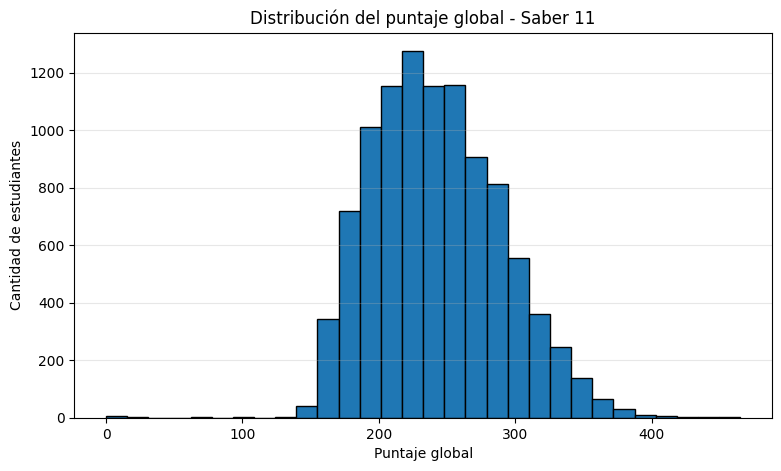

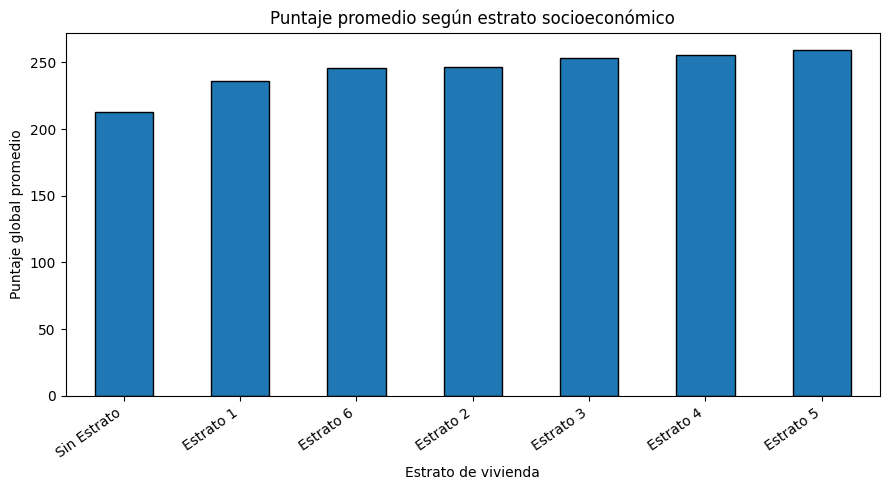

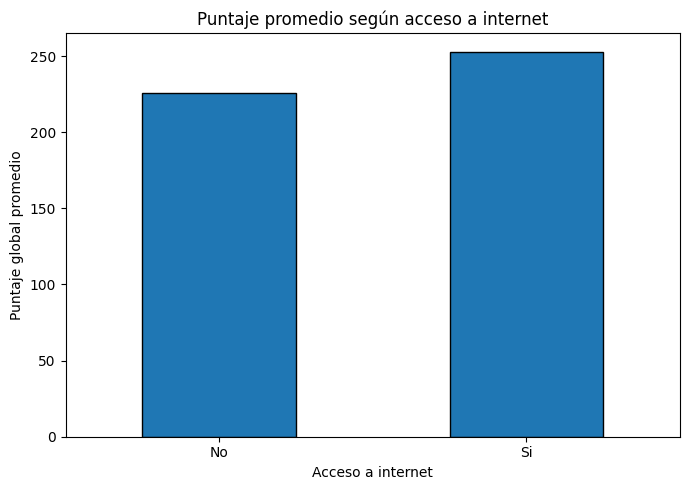

In [6]:

import matplotlib.pyplot as plt
import pandas as pd

# Distribución del puntaje global
puntajes = pd.to_numeric(df["punt_global"], errors="coerce")

plt.figure(figsize=(9, 5))
plt.hist(puntajes.dropna(), bins=30, edgecolor="black")

plt.title("Distribución del puntaje global - Saber 11")
plt.xlabel("Puntaje global")
plt.ylabel("Cantidad de estudiantes")
plt.grid(axis="y", alpha=0.3)
plt.show()

# Puntaje promedio según estrato
datos_estrato = df.copy()
datos_estrato["punt_global"] = puntajes

promedio_estrato = (
    datos_estrato
    .groupby("fami_estratovivienda")["punt_global"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(9, 5))
promedio_estrato.plot(kind="bar", edgecolor="black")

plt.title("Puntaje promedio según estrato socioeconómico")
plt.xlabel("Estrato de vivienda")
plt.ylabel("Puntaje global promedio")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Puntaje promedio según acceso a internet
promedio_internet = (
    datos_estrato
    .groupby("fami_tieneinternet")["punt_global"]
    .mean()
)

plt.figure(figsize=(7, 5))
promedio_internet.plot(kind="bar", edgecolor="black")

plt.title("Puntaje promedio según acceso a internet")
plt.xlabel("Acceso a internet")
plt.ylabel("Puntaje global promedio")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### Interpretación de los resultados exploratorios

**Distribución del puntaje global:** La mayor concentración de estudiantes presenta puntajes aproximadamente entre 180 y 300. Se observan algunos valores extremos que requieren revisión antes de decidir si corresponden a errores o resultados válidos.

**Estrato socioeconómico:** Se observan diferencias en los puntajes promedio según el estrato de vivienda. En general, los estratos más altos presentan mejores promedios, aunque la relación no es completamente uniforme.

**Acceso a internet:** Los estudiantes que reportan acceso a internet en el hogar presentan un puntaje global promedio superior al de quienes no tienen acceso.

**Conclusión preliminar:** Los resultados sugieren asociaciones entre el desempeño académico y algunas condiciones socioeconómicas y tecnológicas. Estas relaciones son descriptivas y no demuestran causalidad.

**Limitación:** Se analizaron los primeros 10.000 registros obtenidos mediante la API de datos.gov.co. Por tanto, los resultados no deben generalizarse automáticamente a toda la población estudiantil colombiana.


In [7]:

# ==========================================
# REVISIÓN DE PUNTAJES EXTREMOS
# ==========================================

print("Estadísticas del puntaje global:")
display(df["punt_global"].describe())

print("\nCantidad de estudiantes por estrato:")
display(df["fami_estratovivienda"].value_counts(dropna=False))

print("\nCantidad de estudiantes según acceso a internet:")
display(df["fami_tieneinternet"].value_counts(dropna=False))

print("\nRegistros con puntajes globales muy bajos:")
display(
    df.loc[
        df["punt_global"] < 100,
        ["punt_global", "periodo", "fami_estratovivienda"]
    ].head(15)
)


Estadísticas del puntaje global:


,punt_global
count,10000.000000
mean,241.902400
std,46.992228
min,0.000000
25%,206.000000
50%,238.000000
75%,273.000000
max,465.000000



Cantidad de estudiantes por estrato:


,count
fami_estratovivienda,
Estrato 2,3325
Estrato 1,3126
Estrato 3,1826
Sin Estrato,634
Estrato 4,459
NaN,396
Estrato 5,141
Estrato 6,93



Cantidad de estudiantes según acceso a internet:


,count
fami_tieneinternet,
Si,5996
No,3698
NaN,306



Registros con puntajes globales muy bajos:


,punt_global,periodo,fami_estratovivienda
785,12,20204,NaN
1001,72,20204,Sin Estrato
1732,0,20204,NaN
2066,0,20204,NaN
3554,25,20204,NaN
4633,28,20204,NaN
4749,0,20204,NaN
6266,0,20204,NaN



## 3. Revisión de valores atípicos e inconsistencias

Se identificaron registros con puntajes globales inferiores a 100, incluidos algunos con valor cero.

Antes de realizar cualquier eliminación, se revisarán los puntajes de las pruebas individuales y la información asociada a estos registros, con el fin de determinar si existen inconsistencias o resultados que requieran un tratamiento especial.

Los valores extremos no se consideran errores automáticamente.



In [8]:

# ==========================================
# REVISIÓN DE PUNTAJES ATÍPICOS
# ==========================================

columnas_puntajes = [
    "punt_global",
    "punt_matematicas",
    "punt_lectura_critica",
    "punt_sociales_ciudadanas",
    "punt_c_naturales",
    "punt_ingles"
]

# Comprobar qué columnas están disponibles
disponibles = [
    col for col in columnas_puntajes
    if col in df.columns
]

print("Columnas de puntajes encontradas:")
print(disponibles)

# Revisar registros con puntaje global inferior a 100
atipicos = df.loc[
    df["punt_global"] < 100,
    disponibles
]

print("\nCantidad de registros con puntaje inferior a 100:")
print(len(atipicos))

display(atipicos)

# Revisar rangos de puntajes
print("\nEstadísticas de los puntajes:")
display(df[disponibles].describe().T)

# Revisar posibles puntajes fuera del rango esperado
print("\nPuntajes globales fuera del rango 0-500:")
print(
    (
        (df["punt_global"] < 0) |
        (df["punt_global"] > 500)
    ).sum()
)



Columnas de puntajes encontradas:
['punt_global', 'punt_matematicas', 'punt_lectura_critica', 'punt_sociales_ciudadanas', 'punt_c_naturales', 'punt_ingles']

Cantidad de registros con puntaje inferior a 100:
8


,punt_global,punt_matematicas,punt_lectura_critica,punt_sociales_ciudadanas,punt_c_naturales,punt_ingles
785,12,0,0,0,0,31.0
1001,72,0,26,27,0,28.0
1732,0,0,0,0,0,NaN
2066,0,0,0,0,0,0.0
3554,25,0,0,22,0,0.0
4633,28,0,0,24,0,0.0
4749,0,0,0,0,0,0.0
6266,0,0,0,0,0,0.0



Estadísticas de los puntajes:


,count,mean,std,min,25%,50%,75%,max
punt_global,10000.0,241.902400,46.992228,0.0,206.0,238.0,273.0,465.0
punt_matematicas,10000.0,49.434000,11.414065,0.0,41.0,49.0,57.0,100.0
punt_lectura_critica,10000.0,50.991600,10.013559,0.0,44.0,51.0,58.0,100.0
punt_sociales_ciudadanas,10000.0,46.902000,11.499775,0.0,38.0,46.0,55.0,100.0
punt_c_naturales,10000.0,47.057900,10.196595,0.0,40.0,47.0,54.0,100.0
punt_ingles,9995.0,45.785893,11.091366,0.0,38.0,44.0,51.0,100.0



Puntajes globales fuera del rango 0-500:
0



## 4. Limpieza y control de calidad de los datos

Durante la exploración se identificaron ocho registros con puntajes globales inferiores a 100. Estos registros presentan puntuaciones de cero en varias pruebas individuales, por lo que se consideran casos que requieren revisión.

No se asume que sean errores de captura. Se conservarán en el dataset original y se marcarán para realizar un análisis de sensibilidad antes de decidir si deben excluirse del modelado.

Los valores faltantes de las variables predictoras se conservarán en esta etapa. Su tratamiento se realizará posteriormente mediante técnicas de imputación ajustadas exclusivamente con los datos de entrenamiento, para evitar fuga de información.


In [9]:

# ==========================================
# LIMPIEZA INICIAL DEL DATASET
# ==========================================

# Crear una copia para no modificar los datos originales
df_limpio = df.copy()

# Eliminar filas completamente duplicadas
duplicados = df_limpio.duplicated().sum()
df_limpio = df_limpio.drop_duplicates().copy()

# Convertir el puntaje global a numérico
df_limpio["punt_global"] = pd.to_numeric(
    df_limpio["punt_global"],
    errors="coerce"
)

# Marcar puntajes que requieren revisión
df_limpio["puntaje_atipico_revision"] = (
    df_limpio["punt_global"] < 100
)

# Comprobar puntajes fuera del rango válido
fuera_rango = (
    (df_limpio["punt_global"] < 0) |
    (df_limpio["punt_global"] > 500)
)

print("Duplicados eliminados:", duplicados)
print("Puntajes fuera del rango 0-500:", fuera_rango.sum())
print(
    "Puntajes inferiores a 100 para revisión:",
    df_limpio["puntaje_atipico_revision"].sum()
)

print("\nDimensiones del dataset limpio:")
print(df_limpio.shape)

# Guardar el dataset con los registros conservados
df_limpio.to_csv(
    "/content/saber11_limpio.csv",
    index=False
)

print("\nArchivo saber11_limpio.csv guardado correctamente.")


Duplicados eliminados: 0
Puntajes fuera del rango 0-500: 0
Puntajes inferiores a 100 para revisión: 8

Dimensiones del dataset limpio:
(10000, 82)

Archivo saber11_limpio.csv guardado correctamente.



## 5. Selección inicial de variables

Para estudiar la relación entre las condiciones socioeconómicas y educativas y el desempeño académico, se propone un conjunto inicial de variables familiares, tecnológicas, institucionales y demográficas.

Se conserva `punt_global` como variable objetivo para el modelado posterior.

No se incluyen los puntajes de las pruebas individuales como variables predictoras, debido a su relación directa con el puntaje global, lo que podría generar fuga de información.

La selección definitiva de características y la transformación de variables se realizarán durante la etapa de preparación y modelado.


In [10]:

# ==========================================
# SELECCIÓN INICIAL DE VARIABLES
# ==========================================

columnas_modelo = [
    "fami_estratovivienda",
    "fami_educacionmadre",
    "fami_educacionpadre",
    "fami_tieneinternet",
    "fami_tienecomputador",
    "cole_naturaleza",
    "cole_area_ubicacion",
    "estu_genero",
    "punt_global"
]

# Verificar que existan todas las columnas
faltantes = [
    col for col in columnas_modelo
    if col not in df_limpio.columns
]

if faltantes:
    raise ValueError(
        f"Estas columnas no existen: {faltantes}"
    )

# Crear dataset de trabajo para modelado
df_modelo = df_limpio[columnas_modelo].copy()

print("Dimensiones del dataset para modelado:")
print(df_modelo.shape)

print("\nValores nulos por variable:")
display(df_modelo.isnull().sum())

print("\nPrimeros registros:")
display(df_modelo.head())

# Guardar el archivo
df_modelo.to_csv(
    "/content/saber11_modelado.csv",
    index=False
)

print("\nArchivo saber11_modelado.csv guardado.")


Dimensiones del dataset para modelado:
(10000, 9)

Valores nulos por variable:


,0
fami_estratovivienda,396
fami_educacionmadre,310
fami_educacionpadre,298
fami_tieneinternet,306
fami_tienecomputador,445
cole_naturaleza,0
cole_area_ubicacion,0
estu_genero,0
punt_global,0



Primeros registros:


,fami_estratovivienda,fami_educacionmadre,fami_educacionpadre,fami_tieneinternet,fami_tienecomputador,cole_naturaleza,cole_area_ubicacion,estu_genero,punt_global
0,Estrato 2,Educación profesional completa,Técnica o tecnológica completa,Si,Si,OFICIAL,RURAL,F,244
1,Estrato 3,Educación profesional completa,Secundaria (Bachillerato) completa,Si,No,OFICIAL,RURAL,M,238
2,Estrato 1,Secundaria (Bachillerato) incompleta,Primaria incompleta,No,No,OFICIAL,RURAL,F,325
3,Sin Estrato,Educación profesional completa,Secundaria (Bachillerato) incompleta,Si,No,OFICIAL,RURAL,M,238
4,Estrato 5,Educación profesional completa,Secundaria (Bachillerato) completa,Si,Si,OFICIAL,URBANO,F,202



Archivo saber11_modelado.csv guardado.


## 6. Resumen de limpieza y preparación para el modelado

### Objetivo de la preparación

Preparar el conjunto de datos Saber 11 para analizar la relación
entre las características socioeconómicas, familiares y educativas
de los estudiantes y su puntaje global.

### Decisiones metodológicas

1. **Selección de variables:** se conservaron ocho variables
   predictoras relacionadas con el contexto familiar, económico
   y educativo, además de `punt_global` como variable objetivo.

2. **Valores faltantes:** se identificaron durante la exploración.
   Su tratamiento deberá realizarse dentro del proceso de
   entrenamiento para evitar fugas de información.

3. **Registros duplicados:** se revisaron para identificar posibles
   repeticiones en el conjunto de datos.

4. **Valores atípicos:** los puntajes inusuales no se eliminaron
   automáticamente, ya que primero es necesario comprobar
   si corresponden a registros válidos.

5. **Preparación para Machine Learning:** las variables categóricas
   deberán transformarse a una representación numérica adecuada
   mediante un preprocesamiento ajustado únicamente con los
   datos de entrenamiento.

### Consideraciones

Los datos utilizados corresponden a los primeros 10.000 registros
consultados de Saber 11 2020-2. Por lo tanto, los resultados
no deben generalizarse automáticamente a todos los estudiantes
de Colombia.

In [12]:

# ==========================================
# RESUMEN FINAL DE LIMPIEZA
# ==========================================

import pandas as pd

resumen_limpieza = pd.DataFrame({
    "Indicador": [
        "Registros originales",
        "Registros duplicados eliminados",
        "Registros después de la limpieza",
        "Puntajes inferiores a 100 (en revisión)",
        "Registros preparados para modelado",
        "Variables predictoras",
        "Variable objetivo"
    ],
    "Resultado": [
        len(df),
        int(duplicados),
        len(df_limpio),
        int(df_limpio["puntaje_atipico_revision"].sum()),
        len(df_modelo),
        len(df_modelo.columns) - 1,
        "punt_global"
    ]
})

print("RESUMEN DE LIMPIEZA Y PREPARACIÓN")
display(resumen_limpieza)

print("\nPORCENTAJE DE VALORES FALTANTES POR VARIABLE")
porcentaje_nulos = (
    df_modelo.isna().mean() * 100
).round(2)

display(
    porcentaje_nulos
    .rename("Porcentaje de nulos (%)")
    .to_frame()
)


RESUMEN DE LIMPIEZA Y PREPARACIÓN


,Indicador,Resultado
0,Registros originales,10000
1,Registros duplicados eliminados,0
2,Registros después de la limpieza,10000
3,Puntajes inferiores a 100 (en revisión),8
4,Registros preparados para modelado,10000
5,Variables predictoras,8
6,Variable objetivo,punt_global



PORCENTAJE DE VALORES FALTANTES POR VARIABLE


,Porcentaje de nulos (%)
fami_estratovivienda,3.96
fami_educacionmadre,3.10
fami_educacionpadre,2.98
fami_tieneinternet,3.06
fami_tienecomputador,4.45
cole_naturaleza,0.00
cole_area_ubicacion,0.00
estu_genero,0.00
punt_global,0.00


### 6.1. Conclusiones del proceso de limpieza

El conjunto de datos utilizado para el análisis contiene 10.000 registros correspondientes a las pruebas Saber 11 del periodo 2020-2, obtenidos del portal oficial de Datos Abiertos de Colombia.

Durante la exploración y limpieza se identificaron los siguientes resultados:

- **Registros duplicados:** no se encontraron registros duplicados que requirieran eliminación, por lo que se conservaron los 10.000 registros originales.
- **Valores atípicos:** se identificaron ocho estudiantes con puntajes globales inferiores a 100. Estos registros se conservaron provisionalmente, ya que no existe evidencia suficiente para considerarlos errores.
- **Valores faltantes:** las variables con mayor porcentaje de datos faltantes fueron disponibilidad de computador (4,45 %), estrato socioeconómico (3,96 %) y educación de la madre (3,10 %). También se encontraron valores faltantes en acceso a internet (3,06 %) y educación del padre (2,98 %).
- **Variable objetivo:** `punt_global` no presenta valores faltantes y se utilizará como variable de respuesta para el modelado.
- **Variables predictoras:** se seleccionaron ocho características relacionadas con las condiciones socioeconómicas, familiares y educativas de los estudiantes.

**Justificación de las decisiones**

Se decidió conservar los registros originales para evitar una pérdida innecesaria de información. Los valores faltantes de las variables predictoras se tratarán durante el entrenamiento mediante técnicas de imputación ajustadas exclusivamente con los datos de entrenamiento, evitando fugas de información hacia el conjunto de prueba.

Las variables categóricas se transformarán a una representación numérica adecuada para los algoritmos de Machine Learning.

**Conclusión general**

El proceso de exploración permitió identificar características relevantes del conjunto de datos y establecer las condiciones necesarias para la construcción de modelos predictivos. Los resultados permitirán estudiar la relación entre las condiciones socioeconómicas y educativas de los estudiantes y su desempeño académico, sin asumir que las asociaciones observadas implican causalidad.

Debido a que se utilizaron los primeros 10.000 registros consultados, los resultados no deben interpretarse como representativos de toda la población estudiantil colombiana.